# RAID-KL Student — CNN1D Teacher (v1 fixed τ=7 | v2 adaptive τ∈[2,7] | v3 Vanilla KD)

Train **3 student CNN song song** trong 1 lần chạy — pipeline **y hệt `3-student-dnn-37ft.ipynb`**,
chỉ thay kiến trúc DNN → CNN1D.

- **Teacher:** CNN1D [128,128,256] (Keras). Load → convert PyTorch, sanity-check argmax 100%.
  - `feat_t` (embedding cho adaptive τ của v2) = **feature map flatten trước Dense** (1024-dim),
    tương đương vai trò encoder-output của SSL-CL-DNN / hidden-cuối của DNN.
- **Student:** MiniCNN [32,32,64] (chia /4 filters, giữ độ sâu). Flatten = 256-dim.
- **lr / batch_size:** Optuna teacher CNN (`0.00005` / `512`).
- **Hyperparameter RAID-KL & Vanilla KD giữ NGUYÊN** (α=0.5, λ=0.3, τ_fixed=7, τ∈[2,7], VKD T=3, α=0.5).

Lưu 3 model `.pth` (state_dict), 3 checkpoint độc lập, model size `count_params()×4/1024²`,
biểu đồ lưới 3×3 — tất cả giống hệt bản DNN.


## Cell 1 — Cấu hình & Import

In [1]:
!pip install -q pyarrow pandas scikit-learn torch tensorflow matplotlib seaborn

import os, gc, time, glob, warnings, json, tracemalloc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import (
    classification_report, roc_auc_score,
    accuracy_score, confusion_matrix, f1_score
)

warnings.filterwarnings('ignore')

# ── Duong dan ────────────────────────────────────────────────────────────────
INPUT_DIR    = '/kaggle/input/datasets/rsnngo/37ft-thang3737'
TEACHER_DIR  = '/kaggle/input/datasets/rsnngo/teacher-model-thang3737'
TEACHER_KERAS_PATH = f'{TEACHER_DIR}/best_model_cnn1d_128_128_256.keras'
TEACHER_PTH_CACHE  = '/kaggle/working/teacher_cnn_converted.pth'

OUTPUT_DIR   = '/kaggle/working/'
TRAIN_FILE   = os.path.join(INPUT_DIR, 'train_standard_p3.2.parquet')
VAL_FILE     = os.path.join(INPUT_DIR, 'val_standard_p3.2.parquet')
TEST_FILE    = os.path.join(INPUT_DIR, 'test_standard_p3.2.parquet')
CLASS_WEIGHTS_JSON = os.path.join(INPUT_DIR, 'class_weights_p3.2.json')

V1_PATH      = os.path.join(OUTPUT_DIR, 'student_cnn_fix_t_classw3_37ft.pth')
V2_PATH      = os.path.join(OUTPUT_DIR, 'student_cnn_adapt_t_classw3_37ft.pth')
V3_PATH      = os.path.join(OUTPUT_DIR, 'student_cnn_vanilla_kd_classw3_37ft.pth')
V1_CKPT_DIR  = os.path.join(OUTPUT_DIR, 'ckpt_v1')
V2_CKPT_DIR  = os.path.join(OUTPUT_DIR, 'ckpt_v2')
V3_CKPT_DIR  = os.path.join(OUTPUT_DIR, 'ckpt_v3')
for d in [OUTPUT_DIR, V1_CKPT_DIR, V2_CKPT_DIR, V3_CKPT_DIR]:
    os.makedirs(d, exist_ok=True)

# ── Hang so model ─────────────────────────────────────────────────────────────
NUM_FEATURES = 37
NUM_CLASSES  = 8
LABEL_COL    = 'label'
FILTERS_TEACHER = [128, 128, 256]
FILTERS_STUDENT = [32, 32, 64]
KERNEL_SIZE  = 3
DROPOUT_RATE = 0.1
TEACHER_EMBED_DIM = 1024   # flatten dim teacher (L=4 x 256ch)
STUDENT_EMBED_DIM = 256    # flatten dim student (L=4 x 64ch)
FLAT_LEN          = NUM_FEATURES // (2 ** len(FILTERS_TEACHER))   # 37//8 = 4 (length sau conv cuoi)
LABEL_NAMES = {0:'Benign',1:'DDoS',2:'DoS',3:'BruteForce',
               4:'Spoofing',5:'Recon',6:'Web-Based',7:'Mirai'}
CLASS_NAMES = [LABEL_NAMES[i] for i in range(NUM_CLASSES)]
COLORS = ['#4C9BE8','#E84C4C','#F5A623','#9B59B6',
          '#2ECC71','#1ABC9C','#8B4513','#607D8B']

# ── Hyperparameters training (lr & batch tu Optuna teacher CNN) ──────────────
BATCH_SIZE       = 512
N_EPOCHS         = 50
LR               = 0.00005
WEIGHT_DECAY     = 0.01
CHECKPOINT_EVERY = 5
RANDOM_SEED      = 42
CLASS_WEIGHT_MAX = 3.0

# ── RAID-KL hyperparams (GIU NGUYEN) ─────────────────────────────────────────
ALPHA   = 0.5
LAMBDA  = 0.3
TAU_FIXED = 7.0
TAU_MIN   = 2.0
TAU_MAX   = 7.0

# ── Vanilla KD hyperparams (T=3, alpha=0.5) ──────────────────────────────────
VKD_ALPHA = 0.5
VKD_T     = 3

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('=' * 62)
print('  RAID-KL v1(fixed) + v2(adaptive) + Vanilla KD (CNN1D)')
print('=' * 62)
print(f'  Device     : {DEVICE}')
print(f'  Batch size : {BATCH_SIZE}   LR: {LR}   WD: {WEIGHT_DECAY}')
print(f'  N_EPOCHS   : {N_EPOCHS}')
print(f'  α={ALPHA}  λ={LAMBDA}')
print(f'  v1 τ={TAU_FIXED} (fixed) | v2 τ∈[{TAU_MIN},{TAU_MAX}] (adaptive)')
print(f'  VKD α={VKD_ALPHA} T={VKD_T}')
print('=' * 62)


  RAID-KL v1(fixed) + v2(adaptive) + Vanilla KD (CNN1D)
  Device     : cuda
  Batch size : 512   LR: 5e-05   WD: 0.01
  N_EPOCHS   : 50
  α=0.5  λ=0.3
  v1 τ=7.0 (fixed) | v2 τ∈[2.0,7.0] (adaptive)
  VKD α=0.5 T=3


## Load class weights (`weights_balanced`, clip max=3)

In [2]:
def load_class_weights(json_path, num_classes=NUM_CLASSES, clip_max=CLASS_WEIGHT_MAX):
    """Doc class_weights_p3.json, lay 'weights_balanced', clip max."""
    with open(json_path, 'r') as f:
        raw = json.load(f)
    weights = np.ones(num_classes, dtype=np.float32)
    if isinstance(raw, dict) and any(k in raw for k in ('weights_balanced','class_weights','weights')):
        for key in ('weights_balanced','class_weights','weights'):
            if key in raw:
                arr = raw[key]
                assert len(arr) == num_classes, f'{key} len {len(arr)} != {num_classes}'
                weights = np.array(arr, dtype=np.float32)
                print(f'  Lay class weight tu key "{key}"')
                break
    elif isinstance(raw, list):
        assert len(raw) == num_classes
        weights = np.array(raw, dtype=np.float32)
    elif isinstance(raw, dict):
        name_to_idx = {v: k for k, v in LABEL_NAMES.items()}
        for k, val in raw.items():
            idx = int(k) if str(k).isdigit() else name_to_idx[k]
            weights[idx] = float(val)
    weights_clipped = np.minimum(weights, clip_max)
    return torch.tensor(weights_clipped, dtype=torch.float32, device=DEVICE), weights

try:
    class_weights, class_weights_raw = load_class_weights(CLASS_WEIGHTS_JSON)
    print(f'Class weights (balanced -> clip max={CLASS_WEIGHT_MAX:.1f}):')
    for i in range(NUM_CLASSES):
        clip = ' <- CLIP' if class_weights_raw[i] > CLASS_WEIGHT_MAX else ''
        print(f'  [{i}] {LABEL_NAMES[i]:12s}: {class_weights_raw[i]:8.4f} -> {class_weights[i].item():.4f}{clip}')
except FileNotFoundError:
    print(f'CANH BAO: khong thay {CLASS_WEIGHTS_JSON} -> class_weights=None')
    class_weights = None


  Lay class weight tu key "weights_balanced"
Class weights (balanced -> clip max=3.0):
  [0] Benign      :   0.8334 -> 0.8334
  [1] DDoS        :   0.2914 -> 0.2914
  [2] DoS         :   0.9012 -> 0.9012
  [3] BruteForce  :  69.7046 -> 3.0000 <- CLIP
  [4] Spoofing    :   2.0023 -> 2.0023
  [5] Recon       :   1.4567 -> 1.4567
  [6] Web-Based   :  36.8116 -> 3.0000 <- CLIP
  [7] Mirai       :   0.9697 -> 0.9697


## Cell 2 — Dataset (reshape (N,1,37) cho Conv1d)

In [3]:
class ParquetDataset(Dataset):
    def __init__(self, path, label_col=LABEL_COL):
        df = pd.read_parquet(path)
        feat_cols = [c for c in df.columns if c != label_col]
        assert len(feat_cols) == NUM_FEATURES, f'{len(feat_cols)} != {NUM_FEATURES}'
        X = df[feat_cols].to_numpy(dtype=np.float32)
        self.X = torch.from_numpy(X).unsqueeze(1)   # (N, 1, 37)
        self.y = torch.from_numpy(df[label_col].to_numpy(dtype=np.int64))
        print(f'  {path.split("/")[-1]}: {len(self.X):,} mau, shape {tuple(self.X.shape[1:])}')
    def __len__(self):        return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]

print('Dang doc du lieu ...')
train_ds = ParquetDataset(TRAIN_FILE)
val_ds   = ParquetDataset(VAL_FILE)
test_ds  = ParquetDataset(TEST_FILE)

kw = dict(batch_size=BATCH_SIZE, num_workers=2, pin_memory=True)
train_loader = DataLoader(train_ds, shuffle=True,  **kw)
val_loader   = DataLoader(val_ds,   shuffle=False, **kw)
test_loader  = DataLoader(test_ds,  shuffle=False, **kw)
print(f'Dataset san sang | train {len(train_loader):,} batches')


Dang doc du lieu ...
  train_standard_p3.2.parquet: 4,468,344 mau, shape (1, 37)
  val_standard_p3.2.parquet: 1,117,087 mau, shape (1, 37)
  test_standard_p3.2.parquet: 1,396,358 mau, shape (1, 37)
Dataset san sang | train 8,728 batches


## Cell 3 — Kiến trúc Teacher & 3 Student

- Teacher `CNN1DWithFeat`: `forward_feat()` trả (logits, feat) — feat = flatten trước Dense (1024-dim).
- StudentV1 (fixed τ): MiniCNN, không proj.
- StudentV2 (adaptive τ): MiniCNN + `proj(256→1024)` để so cosine với feat_t.
- StudentV3 (Vanilla KD): MiniCNN, không proj.


In [4]:
def _make_blocks(in_ch, filters, kernel, dropout, in_len):
    blocks = nn.ModuleList()
    ch, L = in_ch, in_len
    for f in filters:
        blocks.append(nn.Sequential(
            nn.Conv1d(ch, f, kernel_size=kernel, padding='same'), nn.ReLU(),
            nn.MaxPool1d(2), nn.BatchNorm1d(f, eps=1e-3), nn.Dropout(dropout)))
        ch, L = f, L // 2
    return blocks, L * ch


# ── Teacher CNN1D [128,128,256] ──────────────────────────────────────────────
class CNN1DWithFeat(nn.Module):
    def __init__(self, in_ch=1, filters=FILTERS_TEACHER, num_classes=NUM_CLASSES,
                 kernel=KERNEL_SIZE, dropout=DROPOUT_RATE, in_len=NUM_FEATURES):
        super().__init__()
        self.blocks, self.flat_dim = _make_blocks(in_ch, filters, kernel, dropout, in_len)
        self.head = nn.Linear(self.flat_dim, num_classes)
    def forward(self, x):
        for b in self.blocks: x = b(x)
        return self.head(x.flatten(1))
    def forward_feat(self, x):
        """Tra (logits, feat) -- feat = flatten truoc Dense (1024-dim) cho adaptive τ."""
        for b in self.blocks: x = b(x)
        feat = x.flatten(1)
        return self.head(feat), feat


# ── Student MiniCNN body [32,32,64] ──────────────────────────────────────────
class MiniCNNBody(nn.Module):
    def __init__(self, in_ch=1, filters=FILTERS_STUDENT, kernel=KERNEL_SIZE,
                 dropout=DROPOUT_RATE, in_len=NUM_FEATURES):
        super().__init__()
        self.blocks, self.flat_dim = _make_blocks(in_ch, filters, kernel, dropout, in_len)
    def forward(self, x):
        for b in self.blocks: x = b(x)
        return x.flatten(1)   # [B, 256]


class StudentV1(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = MiniCNNBody()
        self.head = nn.Linear(self.body.flat_dim, NUM_CLASSES)
    def forward(self, x):
        return self.head(self.body(x))


class StudentV2(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = MiniCNNBody()
        self.head = nn.Linear(self.body.flat_dim, NUM_CLASSES)
        self.proj = nn.Linear(self.body.flat_dim, TEACHER_EMBED_DIM, bias=False)  # 256->1024
    def forward(self, x):
        feat      = self.body(x)          # [B,256]
        logits    = self.head(feat)
        feat_proj = self.proj(feat)       # [B,1024] -- adaptive τ
        return logits, feat_proj


class StudentV3(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = MiniCNNBody()
        self.head = nn.Linear(self.body.flat_dim, NUM_CLASSES)
    def forward(self, x):
        return self.head(self.body(x))


def count_params(m): return sum(p.numel() for p in m.parameters())

_t  = count_params(CNN1DWithFeat())
_v1 = count_params(StudentV1())
_v2 = count_params(StudentV2())
_v3 = count_params(StudentV3())
print(f'Teacher params  : {_t:,}')
print(f'Student v1      : {_v1:,}  (khong proj)  compression {1-_v1/_t:.1%}')
print(f'Student v2      : {_v2:,}  (co proj)     compression {1-_v2/_t:.1%}')
print(f'Student v3 (VKD): {_v3:,}  (khong proj)  compression {1-_v3/_t:.1%}')
print('Kien truc san sang')


Teacher params  : 157,576
Student v1      : 11,752  (khong proj)  compression 92.5%
Student v2      : 273,896  (co proj)     compression -73.8%
Student v3 (VKD): 11,752  (khong proj)  compression 92.5%
Kien truc san sang


## Cell 4 — Loss Functions (giữ nguyên y hệt bản DNN)

In [5]:
def js_divergence(p, q):
    m     = 0.5 * (p + q)
    kl_pm = F.kl_div((m + 1e-8).log(), p + 1e-8, reduction='batchmean')
    kl_qm = F.kl_div((m + 1e-8).log(), q + 1e-8, reduction='batchmean')
    return 0.5 * kl_pm + 0.5 * kl_qm


def ce_weighted(logits, labels):
    return F.cross_entropy(logits, labels, weight=class_weights)

def raid_kl_loss_v1(logits_s, logits_t, labels):
    tau = TAU_FIXED
    p_t = F.softmax(logits_t / tau, dim=-1)
    p_s = F.softmax(logits_s / tau, dim=-1)
    kl  = F.kl_div((p_s + 1e-8).log(), p_t + 1e-8, reduction='batchmean')
    js  = js_divergence(p_t, p_s)
    L_ce = ce_weighted(logits_s, labels)
    return (1.0 - LAMBDA) * L_ce + LAMBDA * (tau ** 2) * (ALPHA * kl + (1.0 - ALPHA) * js)


def adaptive_temperature(feat_t, feat_s_proj):
    ft = F.normalize(feat_t,      dim=-1)
    fs = F.normalize(feat_s_proj, dim=-1)
    cos_sim = (ft * fs).sum(dim=-1).mean()
    tau = TAU_MIN + (TAU_MAX - TAU_MIN) * (1.0 - cos_sim)
    return tau.clamp(TAU_MIN, TAU_MAX)


def raid_kl_loss_v2(logits_s, logits_t, feat_t, feat_s_proj, labels):
    tau = adaptive_temperature(feat_t, feat_s_proj)
    p_t = F.softmax(logits_t / tau, dim=-1)
    p_s = F.softmax(logits_s / tau, dim=-1)
    kl  = F.kl_div((p_s + 1e-8).log(), p_t + 1e-8, reduction='batchmean')
    js  = js_divergence(p_t, p_s)
    L_ce = ce_weighted(logits_s, labels)
    return (1.0 - LAMBDA) * L_ce + LAMBDA * (tau ** 2) * (ALPHA * kl + (1.0 - ALPHA) * js)


def vanilla_kd_loss(logits_s, logits_t, labels):
    p_t     = F.softmax(logits_t / VKD_T, dim=-1)
    log_p_s = F.log_softmax(logits_s / VKD_T, dim=-1)
    L_distill = F.kl_div(log_p_s, p_t, reduction='batchmean') * (VKD_T ** 2)
    L_ce      = ce_weighted(logits_s, labels)
    return VKD_ALPHA * L_distill + (1.0 - VKD_ALPHA) * L_ce


print('Loss functions san sang')
print(f'  raid_kl_loss_v1 : τ = {TAU_FIXED} (fixed)')
print(f'  raid_kl_loss_v2 : τ ∈ [{TAU_MIN}, {TAU_MAX}] (adaptive cosine)')
print(f'  vanilla_kd_loss : α = {VKD_ALPHA}, T = {VKD_T}')


Loss functions san sang
  raid_kl_loss_v1 : τ = 7.0 (fixed)
  raid_kl_loss_v2 : τ ∈ [2.0, 7.0] (adaptive cosine)
  vanilla_kd_loss : α = 0.5, T = 3


## Cell 5 — Load Teacher (Keras → PyTorch, frozen)

In [6]:
import tensorflow as tf

def load_teacher_from_keras(keras_path, cache_path=None):
    """Load Keras CNN1D, build lai PyTorch (Conv->ReLU->Pool->BN->Dropout), copy trong so.
    Keras Conv1D kernel (kernel,in,out) -> PyTorch (out,in,kernel) qua transpose (2,1,0).
    Dense (in,out) -> (out,in). BN eps=1e-3."""
    keras_model = tf.keras.models.load_model(keras_path)
    torch_model = CNN1DWithFeat()

    keras_weighted = [l for l in keras_model.layers if l.get_weights()]
    torch_layers = []
    for block in torch_model.blocks:
        for m in block:
            if isinstance(m, (nn.Conv1d, nn.BatchNorm1d)):
                torch_layers.append(m)
    torch_layers.append(torch_model.head)

    assert len(keras_weighted) == len(torch_layers), (
        f'So layer khong khop: Keras={len(keras_weighted)}, PyTorch={len(torch_layers)}.')

    for k_layer, t_layer in zip(keras_weighted, torch_layers):
        wts = k_layer.get_weights()
        if isinstance(t_layer, nn.Conv1d):
            W, b = wts
            W_t = np.transpose(W, (2, 1, 0))
            t_layer.weight.data = torch.from_numpy(W_t.copy()).float()
            t_layer.bias.data   = torch.from_numpy(b).float()
        elif isinstance(t_layer, nn.BatchNorm1d):
            gamma, beta, mean, var = wts
            t_layer.weight.data       = torch.from_numpy(gamma).float()
            t_layer.bias.data         = torch.from_numpy(beta).float()
            t_layer.running_mean.data = torch.from_numpy(mean).float()
            t_layer.running_var.data  = torch.from_numpy(var).float()
        elif isinstance(t_layer, nn.Linear):
            # Keras Dense flat_dim sap theo (LENGTH, CHANNELS); PyTorch flatten(1) theo (CHANNELS, LENGTH)
            # -> REINDEX hang W truoc khi transpose, neu khong head anh xa sai cot.
            W, b = wts
            flat_dim = W.shape[0]
            C = t_layer.in_features // FLAT_LEN; L = FLAT_LEN
            assert C * L == flat_dim, f'flat mismatch C={C} L={L} flat={flat_dim}'
            perm = np.zeros(flat_dim, dtype=np.int64)
            for c_ in range(C):
                for l_ in range(L):
                    perm[c_ * L + l_] = l_ * C + c_
            t_layer.weight.data = torch.from_numpy(W[perm, :].T.copy()).float()
            t_layer.bias.data   = torch.from_numpy(b).float()

    torch_model.eval()
    if cache_path:
        torch.save(torch_model.state_dict(), cache_path)
        print(f'  Da cache -> {cache_path}')
    return torch_model, keras_model


print('Load & convert teacher CNN tu Keras sang PyTorch ...')
t_model, _keras_teacher = load_teacher_from_keras(TEACHER_KERAS_PATH, cache_path=TEACHER_PTH_CACHE)
t_model.to(DEVICE).eval()
for p in t_model.parameters(): p.requires_grad = False

t_params = count_params(t_model)
print(f'Teacher loaded | Params: {t_params:,} | Frozen: True | flat_dim={t_model.flat_dim}')

@torch.no_grad()
def teacher_forward(x):
    return t_model.forward_feat(x)   # (logits_t, feat_t 1024-dim)

# ── Sanity check: Keras (N,37,1) channels-last vs PyTorch (N,1,37) ──
_x_np    = train_ds.X[:256].numpy()
_x_keras = np.transpose(_x_np, (0, 2, 1))
_x_torch = train_ds.X[:256].to(DEVICE)
_keras_pred = np.argmax(_keras_teacher.predict(_x_keras, verbose=0), axis=1)
_lt, _ft    = teacher_forward(_x_torch)
_torch_pred = _lt.argmax(dim=1).cpu().numpy()

assert np.array_equal(_keras_pred, _torch_pred), (
    'CONVERT LOI: PyTorch teacher KHONG khop Keras! Kiem tra transpose kernel.')
print(f'Sanity check: Keras vs PyTorch teacher argmax khop 100% ({len(_keras_pred)} mau)')
print(f'Teacher sanity: logits {tuple(_lt.shape)}, feat {tuple(_ft.shape)} (ky vong feat [B, {TEACHER_EMBED_DIM}])')
assert _ft.shape[1] == TEACHER_EMBED_DIM
del _x_np, _x_keras, _x_torch, _keras_pred, _lt, _ft, _torch_pred
gc.collect()


Load & convert teacher CNN tu Keras sang PyTorch ...


I0000 00:00:1785772387.301102      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13754 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1785772387.303357      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


  Da cache -> /kaggle/working/teacher_cnn_converted.pth
Teacher loaded | Params: 157,576 | Frozen: True | flat_dim=1024


I0000 00:00:1785772390.158588      82 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Sanity check: Keras vs PyTorch teacher argmax khop 100% (256 mau)
Teacher sanity: logits (256, 8), feat (256, 1024) (ky vong feat [B, 1024])


300

## Cell 6 — Khởi tạo 3 Student & Optimizer (auto-resume độc lập)

In [7]:
def find_latest_ckpt(ckpt_dir):
    files = sorted(glob.glob(os.path.join(ckpt_dir, 'ckpt_student_epoch_*.pth')))
    return files[-1] if files else None

def init_student(model_cls, ckpt_dir, version):
    student   = model_cls().to(DEVICE)
    optimizer = optim.Adam(student.parameters(), lr=LR)
    start_epoch = 1
    train_losses, val_losses = [], []
    best_val_loss = float('inf')
    best_state    = None

    latest = find_latest_ckpt(ckpt_dir)
    if latest:
        ck = torch.load(latest, map_location='cpu')
        student.load_state_dict(ck['model_state']); student.to(DEVICE)
        start_epoch   = ck['epoch'] + 1
        train_losses  = ck.get('train_losses',  [])
        val_losses    = ck.get('val_losses',    [])
        best_val_loss = ck.get('best_val_loss', float('inf'))
        best_state    = {k: v.clone() for k, v in student.state_dict().items()}
        print(f'  [{version}] Resume: {os.path.basename(latest)} (tiep epoch {start_epoch})')
    else:
        print(f'  [{version}] Train tu dau')
    return student, optimizer, start_epoch, train_losses, val_losses, best_val_loss, best_state

(student_v1, opt_v1, start_v1, tl_v1, vl_v1, bvl_v1, bs_v1) = init_student(StudentV1, V1_CKPT_DIR, 'v1')
(student_v2, opt_v2, start_v2, tl_v2, vl_v2, bvl_v2, bs_v2) = init_student(StudentV2, V2_CKPT_DIR, 'v2')
(student_v3, opt_v3, start_v3, tl_v3, vl_v3, bvl_v3, bs_v3) = init_student(StudentV3, V3_CKPT_DIR, 'v3')

print(f'\nStudent v1 params : {count_params(student_v1):,}')
print(f'Student v2 params : {count_params(student_v2):,}')
print(f'Student v3 params : {count_params(student_v3):,}')


  [v1] Train tu dau
  [v2] Train tu dau
  [v3] Train tu dau

Student v1 params : 11,752
Student v2 params : 273,896
Student v3 params : 11,752


## Cell 7 — Training Loop (cả 3 student song song, LR cố định)

Mỗi epoch train v1 → v2 → v3 trên cùng batch. Mỗi student lưu best theo val loss riêng, checkpoint độc lập.


In [8]:
def save_ckpt(ckpt_dir, epoch, best_state, tl, vl, bvl):
    path = os.path.join(ckpt_dir, f'ckpt_student_epoch_{epoch:04d}.pth')
    torch.save({'epoch': epoch, 'model_state': best_state,
                'train_losses': tl, 'val_losses': vl, 'best_val_loss': bvl}, path)
    return path


start_epoch = min(start_v1, start_v2, start_v3)

if start_v1 > N_EPOCHS and start_v2 > N_EPOCHS and start_v3 > N_EPOCHS:
    print('Ca 3 student da train xong. Load best state.')
    student_v1.load_state_dict(bs_v1); student_v1.to(DEVICE)
    student_v2.load_state_dict(bs_v2); student_v2.to(DEVICE)
    student_v3.load_state_dict(bs_v3); student_v3.to(DEVICE)
else:
    t_model.eval()
    print(f'[KD] Train tu epoch {start_epoch}/{N_EPOCHS}')
    print(f'{"Epoch":>6} | {"v1 Train":>10} {"v1 Val":>8} | {"v2 Train":>10} {"v2 Val":>8} | {"v3 Train":>10} {"v3 Val":>8} | {"LR":>9}')
    print('-' * 90)
    t0 = time.time()

    for epoch in range(start_epoch, N_EPOCHS + 1):
        student_v1.train(); student_v2.train(); student_v3.train()
        run1, run2, run3, n_seen = 0.0, 0.0, 0.0, 0

        for Xb, yb in train_loader:
            Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
            logits_t, feat_t = teacher_forward(Xb)

            if epoch >= start_v1:
                logits_s1 = student_v1(Xb)
                loss1 = raid_kl_loss_v1(logits_s1, logits_t, yb)
                opt_v1.zero_grad(); loss1.backward(); opt_v1.step()
                run1 += loss1.item() * len(yb)

            if epoch >= start_v2:
                logits_s2, feat_proj = student_v2(Xb)
                loss2 = raid_kl_loss_v2(logits_s2, logits_t, feat_t, feat_proj, yb)
                opt_v2.zero_grad(); loss2.backward(); opt_v2.step()
                run2 += loss2.item() * len(yb)

            if epoch >= start_v3:
                logits_s3 = student_v3(Xb)
                loss3 = vanilla_kd_loss(logits_s3, logits_t, yb)
                opt_v3.zero_grad(); loss3.backward(); opt_v3.step()
                run3 += loss3.item() * len(yb)

            n_seen += len(yb)

        t1 = run1 / max(n_seen, 1); tl_v1.append(t1)
        t2 = run2 / max(n_seen, 1); tl_v2.append(t2)
        t3 = run3 / max(n_seen, 1); tl_v3.append(t3)

        student_v1.eval(); student_v2.eval(); student_v3.eval()
        vr1, vr2, vr3, v_seen = 0.0, 0.0, 0.0, 0
        with torch.no_grad():
            for Xb, yb in val_loader:
                Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
                logits_t, feat_t = teacher_forward(Xb)
                if epoch >= start_v1:
                    vr1 += raid_kl_loss_v1(student_v1(Xb), logits_t, yb).item() * len(yb)
                if epoch >= start_v2:
                    ls2, fp = student_v2(Xb)
                    vr2 += raid_kl_loss_v2(ls2, logits_t, feat_t, fp, yb).item() * len(yb)
                if epoch >= start_v3:
                    ls3 = student_v3(Xb)
                    vr3 += vanilla_kd_loss(ls3, logits_t, yb).item() * len(yb)
                v_seen += len(yb)

        v1 = vr1 / max(v_seen, 1); vl_v1.append(v1)
        v2 = vr2 / max(v_seen, 1); vl_v2.append(v2)
        v3 = vr3 / max(v_seen, 1); vl_v3.append(v3)

        cur_lr = opt_v1.param_groups[0]['lr']

        flag1 = flag2 = flag3 = ''
        if v1 < bvl_v1:
            bvl_v1 = v1; bs_v1 = {k: v.cpu().clone() for k, v in student_v1.state_dict().items()}; flag1 = '*'
        if v2 < bvl_v2:
            bvl_v2 = v2; bs_v2 = {k: v.cpu().clone() for k, v in student_v2.state_dict().items()}; flag2 = '*'
        if v3 < bvl_v3:
            bvl_v3 = v3; bs_v3 = {k: v.cpu().clone() for k, v in student_v3.state_dict().items()}; flag3 = '*'

        print(f'[{epoch:3d}/{N_EPOCHS}] | '
              f'{t1:.4f} {v1:.4f}{flag1:1s} | {t2:.4f} {v2:.4f}{flag2:1s} | '
              f'{t3:.4f} {v3:.4f}{flag3:1s} | {cur_lr:.2e}')

        if epoch % CHECKPOINT_EVERY == 0 or epoch == N_EPOCHS:
            p1 = save_ckpt(V1_CKPT_DIR, epoch, bs_v1, tl_v1, vl_v1, bvl_v1)
            p2 = save_ckpt(V2_CKPT_DIR, epoch, bs_v2, tl_v2, vl_v2, bvl_v2)
            p3 = save_ckpt(V3_CKPT_DIR, epoch, bs_v3, tl_v3, vl_v3, bvl_v3)
            print(f'  [CKPT] {os.path.basename(p1)} | {os.path.basename(p2)} | {os.path.basename(p3)}')

        gc.collect()

    elapsed = time.time() - t0
    student_v1.load_state_dict(bs_v1); student_v1.to(DEVICE)
    student_v2.load_state_dict(bs_v2); student_v2.to(DEVICE)
    student_v3.load_state_dict(bs_v3); student_v3.to(DEVICE)
    torch.save(student_v1.state_dict(), V1_PATH)
    torch.save(student_v2.state_dict(), V2_PATH)
    torch.save(student_v3.state_dict(), V3_PATH)
    print(f'\nTrain xong: {elapsed/60:.1f} phut')
    print(f'  Best v1 val loss: {bvl_v1:.4f} -> {V1_PATH}')
    print(f'  Best v2 val loss: {bvl_v2:.4f} -> {V2_PATH}')
    print(f'  Best v3 val loss: {bvl_v3:.4f} -> {V3_PATH}')


[KD] Train tu epoch 1/50
 Epoch |   v1 Train   v1 Val |   v2 Train   v2 Val |   v3 Train   v3 Val |        LR
------------------------------------------------------------------------------------------
[  1/50] | 1.4455 0.7529* | 1.0305 0.5270* | 1.1777 0.5853* | 5.00e-05
[  2/50] | 0.8452 0.6722* | 0.5660 0.4767* | 0.6399 0.5081* | 5.00e-05
[  3/50] | 0.7822 0.6403* | 0.5269 0.4567* | 0.5829 0.4761* | 5.00e-05
[  4/50] | 0.7483 0.6121* | 0.5067 0.4414* | 0.5540 0.4531* | 5.00e-05
[  5/50] | 0.7251 0.5819* | 0.4921 0.4262* | 0.5317 0.4227* | 5.00e-05
  [CKPT] ckpt_student_epoch_0005.pth | ckpt_student_epoch_0005.pth | ckpt_student_epoch_0005.pth
[  6/50] | 0.6937 0.5400* | 0.4752 0.4093* | 0.5070 0.3963* | 5.00e-05
[  7/50] | 0.6586 0.5062* | 0.4579 0.3957* | 0.4841 0.3743* | 5.00e-05
[  8/50] | 0.6320 0.4825* | 0.4475 0.3867* | 0.4662 0.3601* | 5.00e-05
[  9/50] | 0.6115 0.4680* | 0.4407 0.3830* | 0.4507 0.3486* | 5.00e-05
[ 10/50] | 0.5931 0.4567* | 0.4360 0.3830* | 0.4386 0.3480* | 5

## Cell 8 — Evaluate trên Test Set

In [9]:
def evaluate(student, version, label):
    student.eval()
    all_preds, all_probs, all_labels = [], [], []
    latencies = []

    with torch.no_grad():
        _ = student(test_ds.X[:BATCH_SIZE].to(DEVICE))
    if DEVICE.type == 'cuda': torch.cuda.synchronize()

    tracemalloc.start(); gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.reset_peak_memory_stats()

    with torch.no_grad():
        for Xb, yb in test_loader:
            Xb = Xb.to(DEVICE)
            t0 = time.perf_counter()
            out = student(Xb)
            t1 = time.perf_counter()
            latencies.append((t1 - t0) / len(Xb))
            logits = out[0] if isinstance(out, tuple) else out
            all_probs.append(F.softmax(logits, dim=1).cpu())
            all_preds.append(logits.argmax(dim=1).cpu())
            all_labels.append(yb)

    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    _, ram_peak = tracemalloc.get_traced_memory(); tracemalloc.stop()

    preds  = torch.cat(all_preds).numpy()
    probs  = torch.cat(all_probs).numpy()
    labels = torch.cat(all_labels).numpy()

    acc       = accuracy_score(labels, preds)
    macro_auc = roc_auc_score(labels, probs, multi_class='ovr', average='macro')
    report    = classification_report(labels, preds, target_names=CLASS_NAMES, digits=4)
    n_params  = count_params(student)
    size_mb   = n_params * 4 / 1024**2
    inf_us    = np.mean(latencies) * 1e6
    inf_std   = np.std(latencies)  * 1e6
    ram_mb    = ram_peak / 1024**2
    vram_mb   = (torch.cuda.max_memory_allocated()/1024**2 if DEVICE.type=='cuda' else 0)

    result = (
        f"\n{'='*62}\n"
        f"  {label} -- TEST\n"
        f"{'='*62}\n"
        f"{report}\n"
        f"Accuracy         : {acc:.6f}\n"
        f"Macro AUC        : {macro_auc:.6f}\n"
        f"{'-'*62}\n"
        f"Model size       : {size_mb:.4f} MB  ({size_mb*1024:.2f} KB)\n"
        f"Params (student) : {n_params:,}\n"
        f"Params (teacher) : {t_params:,}\n"
        f"Compression      : {1 - n_params/t_params:.1%}\n"
        f"{'-'*62}\n"
        f"Inference/sample : {inf_us:.2f} +/- {inf_std:.2f} us\n"
        f"RAM peak         : {ram_mb:.2f} MB\n"
        f"VRAM peak        : {vram_mb:.2f} MB\n"
        f"{'='*62}\n"
    )
    print(result)
    with open(os.path.join(OUTPUT_DIR, f'results_{version}.txt'), 'w') as f:
        f.write(result)
    return preds, probs, labels, acc, macro_auc

preds_v1, probs_v1, labels_v1, acc_v1, auc_v1 = evaluate(student_v1, 'v1', 'Student v1 (fixed τ=7)')
preds_v2, probs_v2, labels_v2, acc_v2, auc_v2 = evaluate(student_v2, 'v2', 'Student v2 (adaptive τ∈[2,7])')
preds_v3, probs_v3, labels_v3, acc_v3, auc_v3 = evaluate(student_v3, 'v3', 'Student v3 (Vanilla KD α=0.5, T=3)')



  Student v1 (fixed τ=7) -- TEST
              precision    recall  f1-score   support

      Benign     0.7935    0.7923    0.7929    209448
        DDoS     0.9461    0.7640    0.8453    598978
         DoS     0.5435    0.8636    0.6672    193688
  BruteForce     0.6678    0.2312    0.3435      2504
    Spoofing     0.7482    0.7421    0.7451     87173
       Recon     0.6806    0.7323    0.7055    119826
   Web-Based     0.5485    0.0382    0.0714      4741
       Mirai     0.9980    0.9937    0.9959    180000

    accuracy                         0.8042   1396358
   macro avg     0.7408    0.6447    0.6458   1396358
weighted avg     0.8371    0.8042    0.8104   1396358

Accuracy         : 0.804151
Macro AUC        : 0.971115
--------------------------------------------------------------
Model size       : 0.0448 MB  (45.91 KB)
Params (student) : 11,752
Params (teacher) : 157,576
Compression      : 92.5%
--------------------------------------------------------------
Inference/samp

## Cell 9 — Plots so sánh v1 vs v2 vs v3 (lưới 3×3)

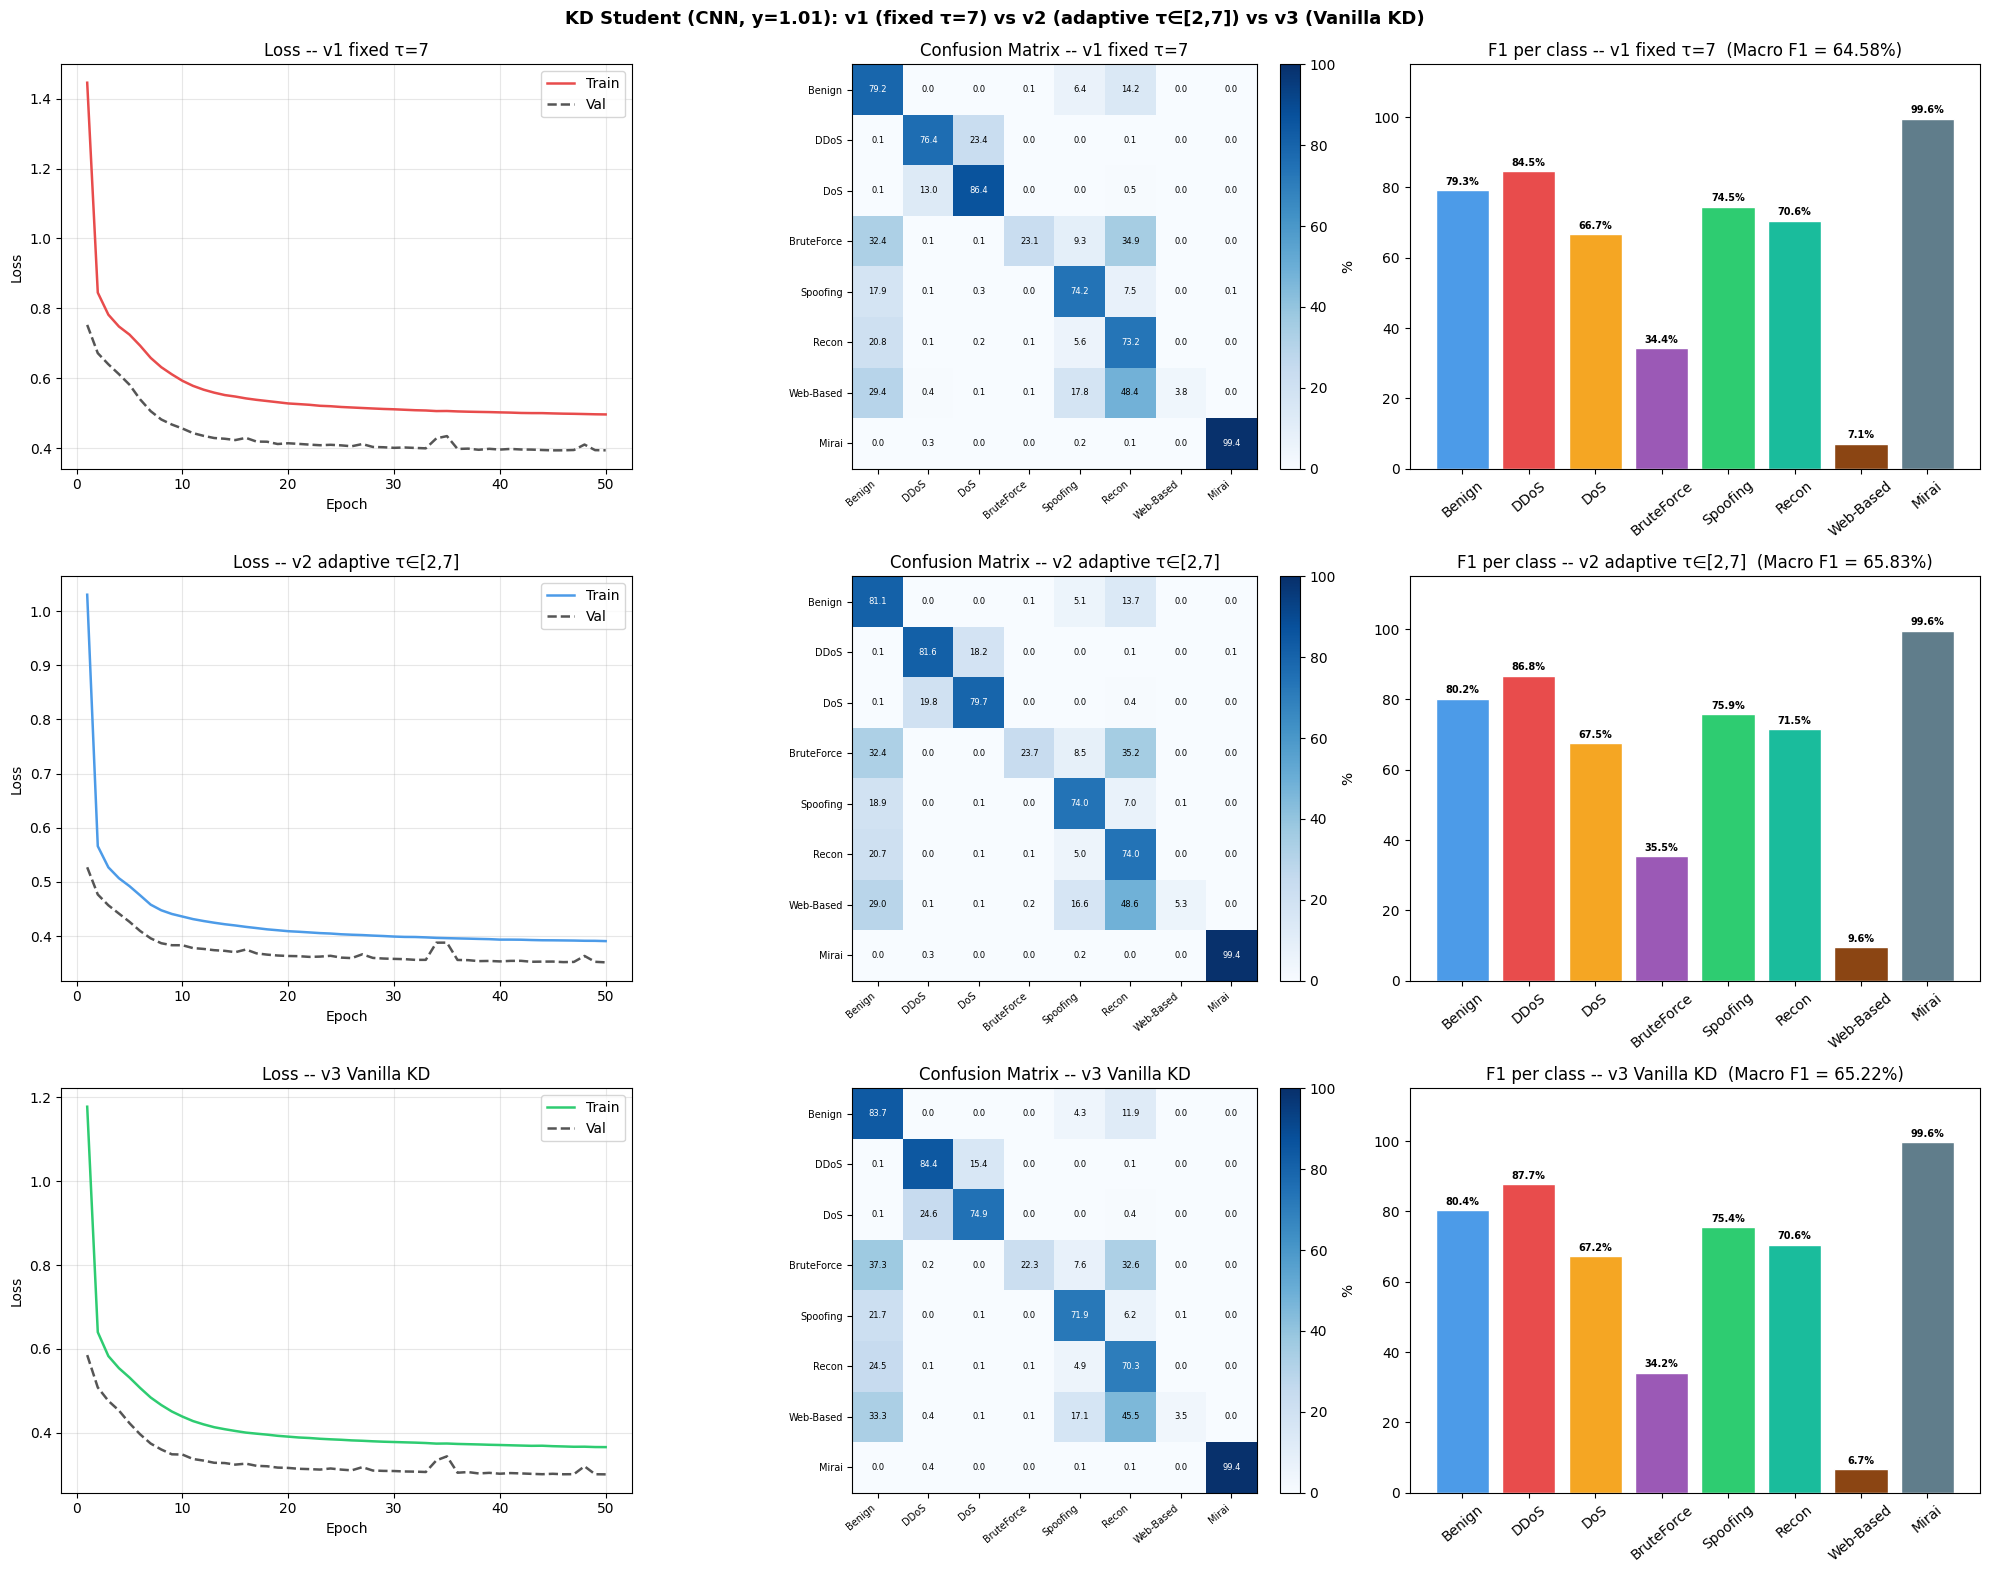

Plot -> /kaggle/working/compare_v1_v2_v3.png


In [10]:
fig, axes = plt.subplots(3, 3, figsize=(20, 16))
fig.suptitle('KD Student (CNN, y=1.01): v1 (fixed τ=7) vs v2 (adaptive τ∈[2,7]) vs v3 (Vanilla KD)',
             fontsize=13, fontweight='bold')

for row, (tl, vl, preds, labels, label, color) in enumerate([
    (tl_v1, vl_v1, preds_v1, labels_v1, 'v1 fixed τ=7',        '#E84C4C'),
    (tl_v2, vl_v2, preds_v2, labels_v2, 'v2 adaptive τ∈[2,7]', '#4C9BE8'),
    (tl_v3, vl_v3, preds_v3, labels_v3, 'v3 Vanilla KD',        '#2ECC71'),
]):
    ep = range(1, len(tl) + 1)
    axes[row,0].plot(ep, tl, label='Train', color=color,    lw=1.8)
    axes[row,0].plot(ep, vl, label='Val',   color='#555555', lw=1.8, linestyle='--')
    axes[row,0].set_title(f'Loss -- {label}')
    axes[row,0].set_xlabel('Epoch'); axes[row,0].set_ylabel('Loss')
    axes[row,0].legend(); axes[row,0].grid(alpha=0.3)

    cm = confusion_matrix(labels, preds)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
    im = axes[row,1].imshow(cm_pct, cmap='Blues', vmin=0, vmax=100)
    plt.colorbar(im, ax=axes[row,1], fraction=0.046, pad=0.04, label='%')
    axes[row,1].set_xticks(range(NUM_CLASSES)); axes[row,1].set_yticks(range(NUM_CLASSES))
    axes[row,1].set_xticklabels(CLASS_NAMES, rotation=40, ha='right', fontsize=7)
    axes[row,1].set_yticklabels(CLASS_NAMES, fontsize=7)
    axes[row,1].set_title(f'Confusion Matrix -- {label}')
    thresh = cm_pct.max() / 2
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            v = cm_pct[i,j]
            axes[row,1].text(j, i, f'{v:.1f}', ha='center', va='center',
                             fontsize=6, color='white' if v > thresh else 'black')

    f1s = f1_score(labels, preds, average=None, zero_division=0)
    bars = axes[row,2].bar(CLASS_NAMES, f1s*100, color=COLORS, edgecolor='white')
    axes[row,2].set_ylim(0, 115)
    axes[row,2].set_title(f'F1 per class -- {label}  (Macro F1 = {np.mean(f1s)*100:.2f}%)')
    axes[row,2].tick_params(axis='x', rotation=40)
    for bar, val in zip(bars, f1s):
        axes[row,2].text(bar.get_x()+bar.get_width()/2, bar.get_height()+1.5,
                         f'{val*100:.1f}%', ha='center', fontsize=7, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.99])
plot_path = os.path.join(OUTPUT_DIR, 'compare_v1_v2_v3.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Plot -> {plot_path}')


## Cell 10 — Export config & ONNX

In [11]:
class StudentInferenceOnly(nn.Module):
    """Wrapper bo proj de export ONNX (body + head only)."""
    def __init__(self, body, head):
        super().__init__()
        self.body = body
        self.head = head
    def forward(self, x): return self.head(self.body(x))


def export_config_onnx(student, version, acc, macro_auc, distill_info):
    n_params = count_params(student)
    config = {
        'model'        : f'KD-Student-{version}-MiniCNN',
        'teacher'      : 'CNN1D-128-128-256',
        'num_features' : NUM_FEATURES,
        'num_classes'  : NUM_CLASSES,
        'teacher_filters': FILTERS_TEACHER,
        'student_filters': FILTERS_STUDENT,
        'distillation' : distill_info,
        'performance'  : {
            'accuracy'    : round(float(acc), 6),
            'macro_auc'   : round(float(macro_auc), 6),
            'params'      : n_params,
            'size_mb_fp32': round(n_params*4/1024**2, 4),
            'compression' : round(1 - n_params/t_params, 4),
        },
    }
    cfg_path = os.path.join(OUTPUT_DIR, f'config_{version}.json')
    with open(cfg_path, 'w') as f: json.dump(config, f, indent=2)
    print(f'Config -> {cfg_path}')

    infer = StudentInferenceOnly(student.body.cpu().eval(), student.head.cpu().eval())
    try:
        onnx_path = os.path.join(OUTPUT_DIR, f'student_cnn_{version}.onnx')
        torch.onnx.export(
            infer, torch.randn(1, 1, NUM_FEATURES), onnx_path,
            input_names=['features'], output_names=['logits'],
            dynamic_axes={'features':{0:'batch'},'logits':{0:'batch'}},
            opset_version=13,
        )
        sz = os.path.getsize(onnx_path)/1024
        print(f'ONNX  -> {onnx_path}  ({sz:.1f} KB)')
    except Exception as e:
        print(f'  ONNX ERROR: {e}')
    student.to(DEVICE)


export_config_onnx(student_v1, 'v1', acc_v1, auc_v1,
                   {'method':'RAID-KL','alpha':ALPHA,'lambda':LAMBDA,'tau':TAU_FIXED,'tau_mode':'fixed'})
export_config_onnx(student_v2, 'v2', acc_v2, auc_v2,
                   {'method':'RAID-KL','alpha':ALPHA,'lambda':LAMBDA,'tau_min':TAU_MIN,'tau_max':TAU_MAX,'tau_mode':'adaptive'})
export_config_onnx(student_v3, 'v3', acc_v3, auc_v3,
                   {'method':'VanillaKD','alpha':VKD_ALPHA,'T':VKD_T})

print('\n' + '='*62)
print('  KET QUA SO SANH')
print('='*62)
print(f'  {"":30s}  {"v1 (fixed τ=7)":>14}  {"v2 (adaptive τ)":>14}  {"v3 (Vanilla KD)":>15}')
print(f'  {"Accuracy":30s}  {acc_v1*100:>13.4f}%  {acc_v2*100:>13.4f}%  {acc_v3*100:>14.4f}%')
print(f'  {"Macro AUC":30s}  {auc_v1:>14.6f}  {auc_v2:>14.6f}  {auc_v3:>15.6f}')
print(f'  {"Params":30s}  {count_params(student_v1):>14,}  {count_params(student_v2):>14,}  {count_params(student_v3):>15,}')
print(f'  {"Size (MB)":30s}  {count_params(student_v1)*4/1024**2:>14.4f}  {count_params(student_v2)*4/1024**2:>14.4f}  {count_params(student_v3)*4/1024**2:>15.4f}')
print('='*62)
print('\nOutput files:')
for fname in sorted(os.listdir(OUTPUT_DIR)):
    fp = os.path.join(OUTPUT_DIR, fname)
    if os.path.isfile(fp):
        print(f'  {fname:<45} {os.path.getsize(fp)/1024:>8.1f} KB')


Config -> /kaggle/working/config_v1.json
  ONNX ERROR: No module named 'onnxscript'
Config -> /kaggle/working/config_v2.json
  ONNX ERROR: No module named 'onnxscript'
Config -> /kaggle/working/config_v3.json
  ONNX ERROR: No module named 'onnxscript'

  KET QUA SO SANH
                                  v1 (fixed τ=7)  v2 (adaptive τ)  v3 (Vanilla KD)
  Accuracy                              80.4151%        82.0544%         82.5178%
  Macro AUC                             0.971115        0.972365         0.972120
  Params                                  11,752         273,896           11,752
  Size (MB)                               0.0448          1.0448           0.0448

Output files:
  __notebook__.ipynb                               465.4 KB
  compare_v1_v2_v3.png                             473.1 KB
  config_v1.json                                     0.5 KB
  config_v2.json                                     0.5 KB
  config_v3.json                                     0.4 KB
  r